# 03 — Cleaning, Preprocessing & Feature Selection
**Project:** Planetary Defense Analytics  
**Inputs:** `data/raw/pha_dataset.csv`  
**Outputs:** case-specific datasets in `data/processed/`, a `03_manifest.json` (paths, transforms, feature sets) and feature-selection tables in `reports/results/`.


## 1. Setup & load

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression, f_classif, f_regression, RFE
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
SEED = 42
rng = np.random.default_rng(SEED)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW_FILE = sorted((ROOT / "data" / "raw").glob("*.csv"))[0]
PROC = ROOT / "data" / "processed"; PROC.mkdir(parents=True, exist_ok=True)
FIG_DIR = ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR = ROOT / "reports" / "results"; RES_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=150); plt.show()

USE = ["full_name", "neo", "pha", "H", "diameter", "albedo", "e", "a", "q", "i",
       "om", "w", "ma", "ad", "n", "per_y", "moid", "moid_ld", "class", "rms"]
df = pd.read_csv(RAW_FILE, usecols=USE, low_memory=False)
print(df.shape)

clean_log = [{"step": "raw load", "rows_before": len(df), "rows_after": len(df), "action": "-"}]
def log(step, before, after, action):
    clean_log.append({"step": step, "rows_before": before, "rows_after": after, "action": action})

(958524, 20)


## 2. Cleaning

### 2.1 Duplicates

In [2]:
n0 = len(df)
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated full_name :", df["full_name"].duplicated().sum())
df = df.drop_duplicates().drop_duplicates(subset="full_name", keep="first").reset_index(drop=True)
log("duplicates", n0, len(df), "drop exact duplicates and repeated full_name (keep first)")
len(df)

Fully duplicated rows: 0
Duplicated full_name : 0


958524

In [3]:
n0 = len(df)
bad_ma = (~df["ma"].between(0, 360)).sum()
df["ma"] = df["ma"] % 360
print(f"ma wrapped: {bad_ma} rows")

hyper = (df["e"] >= 1) | (df["a"] <= 0)
print("Non-bound orbits (e>=1 or a<=0):", hyper.sum())
print(df.loc[hyper, ["full_name", "class", "e", "a"]].to_string(index=False))
df = df.loc[~hyper].reset_index(drop=True)
log("hyperbolic orbits", n0, len(df), "drop e>=1 or a<=0")

for name, cond, col in [("albedo not in (0,1]", (df["albedo"] <= 0) | (df["albedo"] > 1), "albedo"),
                        ("diameter <= 0", df["diameter"] <= 0, "diameter"),
                        ("H not in [0,35]", (df["H"] < 0) | (df["H"] > 35), "H")]:
    k = int(cond.sum()); df.loc[cond, col] = np.nan
    print(f"{name}: {k} values set to NaN")
    log(name, len(df), len(df), f"{k} values -> NaN")

# other sanity checks
print("i outside [0,180]:", (~df["i"].between(0, 180)).sum(), "| moid < 0:", (df["moid"] < 0).sum())

ma wrapped: 96 rows
Non-bound orbits (e>=1 or a<=0): 4
                   full_name class        e             a
                (2013 CA134)   HYA 1.855356     -6.149566
       'Oumuamua (A/2017 U1)   HYA 1.201134     -1.272345
                 (A/2019 G4)   HYA 1.000398 -14702.447872
                 (A/2019 O3)   HYA 1.001173  -7520.984443
albedo not in (0,1]: 0 values set to NaN
diameter <= 0: 0 values set to NaN
H not in [0,35]: 3 values set to NaN
i outside [0,180]: 0 | moid < 0: 0


### 2.3 Missing values — decision per column

In [4]:
miss = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
miss[miss > 0].to_frame("missing_%")

,missing_%
albedo,85.91
diameter,85.79
pha,2.08
moid,2.08
H,0.65
moid_ld,0.01


| Column | Missing | Decision |
|---|---|---|
| `pha`, `moid`, `moid_ld` | ~2.1% (same rows) | Not imputed. Rows without a `pha` label cannot train Case 1. `moid` is excluded anyway (leakage). |
| `H` | ~0.65% | Case 1/2 need it → drop those rows for the case datasets (tiny loss, checked below). |
| `diameter`, `albedo` | ~86% | Not imputed. Case 2 trains only on rows where `diameter` is observed; imputing a *target* would be inventing labels. `albedo` NaN is handled per scenario in notebook 05. |
| `name`, `prefix` | 98-100% | Not loaded (identifiers). |

## 3. Skewness — choose a transform per feature

In [5]:
cands = ["a", "q", "ad", "per_y", "n", "e", "i", "H", "albedo", "diameter", "rms"]
STATELESS = {
    "none":  lambda x: x,
    "sqrt":  np.sqrt,
    "cbrt":  np.cbrt,
    "log10": lambda x: np.log10(x + 1e-6),
}
rows = []
for c in cands:
    x = df[c].dropna()
    r = {"feature": c, "raw_skew": stats.skew(x)}
    for t, f in STATELESS.items():
        if t == "none": continue
        r[t] = stats.skew(f(x)) if x.min() >= 0 else np.nan
    xp = x[x > 0]
    r["inverse"] = stats.skew(1 / xp.sample(min(len(xp), 200_000), random_state=SEED))
    bc, lam = stats.boxcox(xp.sample(min(len(xp), 100_000), random_state=SEED)); r["boxcox"] = stats.skew(bc)
    rows.append(r)
skew_tbl = pd.DataFrame(rows).set_index("feature").round(2)
skew_tbl

,raw_skew,sqrt,cbrt,log10,inverse,boxcox
feature,,,,,,
a,859.26,98.44,20.94,6.25,2.89,-0.92
q,15.84,10.54,7.72,2.29,13.50,-0.49
ad,864.42,140.07,26.79,6.65,1.84,-0.78
per_y,953.00,595.53,98.44,6.25,5.54,-0.92
n,5.62,1.47,-0.26,-6.22,446.57,0.92
e,1.89,0.41,-0.03,-1.15,303.32,0.05
i,2.17,0.49,0.13,-0.65,70.72,-0.01
H,0.61,-0.38,-0.77,-1.71,5.90,0.30
albedo,1.68,0.93,0.74,0.35,27.83,0.04


In [6]:
# Pick the stateless transform with the smallest |skew|.
# Box-Cox / inverse are shown for comparison only: Box-Cox learns lambda from data, so it belongs in a train-fitted pipeline.
feat_for_model = ["a", "q", "ad", "per_y", "n", "e", "i", "H", "albedo"]
chosen = {}
for c in feat_for_model:
    x = df[c].dropna()
    scores = {"none": abs(stats.skew(x))}
    if x.min() >= 0:
        for t in ["sqrt", "cbrt", "log10"]:
            scores[t] = abs(stats.skew(STATELESS[t](x)))
    chosen[c] = min(scores, key=scores.get)
pd.DataFrame({"chosen_transform": chosen,
              "skew_before": {c: stats.skew(df[c].dropna()) for c in chosen},
              "skew_after":  {c: stats.skew(STATELESS[chosen[c]](df[c].dropna())) for c in chosen}}).round(2)

,chosen_transform,skew_before,skew_after
a,log10,859.26,6.25
q,log10,15.84,2.29
ad,log10,864.42,6.65
per_y,log10,953.00,6.25
n,cbrt,5.62,-0.26
e,cbrt,1.89,-0.03
i,cbrt,2.17,0.13
H,sqrt,0.61,-0.38
albedo,log10,1.68,0.35


## 4. Outliers — keep or remove?
IQR-based deletion would remove *real* objects. Quantify what it would destroy before deciding.

In [7]:
flag = pd.Series(False, index=df.index)
for c in ["a", "e", "i"]:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    flag |= (df[c] < q1 - 3 * iqr) | (df[c] > q3 + 3 * iqr)
print(f"Rows a 3*IQR filter on a/e/i would delete: {flag.sum():,} ({flag.mean()*100:.1f}%)")
print("\nBy class:"); print(df.loc[flag, "class"].value_counts().head(8).to_string())
lab = df["pha"].notna()
print(f"\nPHAs deleted: {((df['pha']=='Y') & flag).sum():,} of {(df['pha']=='Y').sum():,}")

Rows a 3*IQR filter on a/e/i would delete: 21,431 (2.2%)

By class:
class
TJN    8210
APO    5931
TNO    3468
AMO    2215
CEN     506
MCA     435
ATE     226
OMB     210

PHAs deleted: 1,225 of 2,066


## 5. Feature engineering (stateless)

In [8]:
for c in feat_for_model:
    df[f"{c}_tr"] = STATELESS[chosen[c]](df[c])

# Cyclic angles -> sin/cos (359 deg and 1 deg become neighbours)
for c in ["om", "w", "ma"]:
    df[f"{c}_sin"] = np.sin(np.deg2rad(df[c])); df[f"{c}_cos"] = np.cos(np.deg2rad(df[c]))

# per_y and n are exact functions of a (Kepler's 3rd law) -> prove it, then keep only `a` in the selection pools
print("|Spearman(a, per_y)| =", round(abs(df["a"].corr(df["per_y"], method="spearman")), 6))
print("|Spearman(a, n)|     =", round(abs(df["a"].corr(df["n"], method="spearman")), 6))
ORB_TR   = ["a_tr", "e_tr", "i_tr", "q_tr", "ad_tr"]   # q = a(1-e), ad = a(1+e) are kept: trees can use them non-linearly
ANGLES   = ["om_sin", "om_cos", "w_sin", "w_cos", "ma_sin", "ma_cos"]
POOLS = {
    "case1_A_noH":         ORB_TR + ANGLES,
    "case1_B_withH":       ORB_TR + ["H_tr"] + ANGLES,
    "case2_A_noAlbedo":    ORB_TR + ["H_tr"] + ANGLES,
    "case2_B_withAlbedo":  ORB_TR + ["H_tr", "albedo_tr"] + ANGLES,
}
print({k: len(v) for k, v in POOLS.items()})

|Spearman(a, per_y)| = 1.0
|Spearman(a, n)|     = 1.0
{'case1_A_noH': 11, 'case1_B_withH': 12, 'case2_A_noAlbedo': 12, 'case2_B_withAlbedo': 13}


## 6. Build case datasets & the train/test split
* **Case 1:** rows with a `pha` label and a valid `H`. **Excluded columns:** `moid`, `moid_ld` (define the label), `neo`, `class` (encode NEO/PHA information).
* **Case 2:** rows with observed `diameter` and `H`. Target = `log10(diameter)`.
* **Case 3:** every bound-orbit row, orbital elements only.

In [9]:
# ---------- Case 1 ----------
n_lab = df["pha"].notna().sum()
c1 = df[df["pha"].notna()].copy()
c1["y_pha"] = (c1["pha"] == "Y").astype(int)
print(f"Case 1: {len(c1):,} rows (lost {n_lab-len(c1):,} to missing H). PHA lost to missing H: {int(((df['pha']=='Y') & df['H'].isna()).sum())}")
tr_idx, te_idx = train_test_split(c1.index, test_size=0.2, stratify=c1["y_pha"], random_state=SEED)
c1["split"] = "train"; c1.loc[te_idx, "split"] = "test"
print(c1.groupby("split")["y_pha"].agg(rows="size", pha="sum", pha_pct=lambda s: round(s.mean()*100, 3)))

# ---------- Case 2 ----------
c2 = df[df["diameter"].notna() & df["H"].notna()].copy()
c2["log_diameter"] = np.log10(c2["diameter"])
tr2, te2 = train_test_split(c2.index, test_size=0.2, random_state=SEED)
c2["split"] = "train"; c2.loc[te2, "split"] = "test"
print(f"\nCase 2: {len(c2):,} rows | albedo present in {c2['albedo'].notna().sum():,}")

# ---------- Case 3 ----------
c3 = df.copy()
print(f"\nCase 3: {len(c3):,} rows")
log("case1 rows", len(df), len(c1), "pha labelled & H present")
log("case2 rows", len(df), len(c2), "diameter & H present")
log("case3 rows", len(df), len(c3), "all bound orbits")

Case 1: 938,599 rows (lost 0 to missing H). PHA lost to missing H: 0
         rows   pha  pha_pct
split                       
test   187720   413     0.22
train  750879  1653     0.22

Case 2: 132,045 rows | albedo present in 131,237

Case 3: 958,520 rows


## 7. Feature selection (train rows only)
Four independent views per scenario, plus a **random-noise probe column**: any feature that ranks below pure noise is useless.

| Method | Family | Captures |
|---|---|---|
| Mutual information | statistical (non-linear) | any dependency with the target |
| ANOVA F / F-regression | statistical (linear) | linear separation / correlation |
| Random-Forest importance | tree-based | non-linear + interactions |
| RFE (logistic / linear) | wrapper | features a linear model can't do without |

Consensus = mean rank of the four.

In [10]:
def rank_features(X, y, task, n_mi=20_000):
    X = X.copy()
    for k in range(1, 6): X[f"noise_probe_{k}"] = rng.normal(size=len(X))   # 5 random columns = the "useless" baseline
    cols = X.columns.tolist()
    Xs = StandardScaler().fit_transform(X)
    sub = rng.choice(len(X), size=min(n_mi, len(X)), replace=False)

    if task == "clf":
        mi = mutual_info_classif(Xs[sub], y[sub], random_state=SEED)
        F  = f_classif(Xs, y)[0]
        rf = RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=5,
                                    class_weight="balanced_subsample", n_jobs=-1, random_state=SEED).fit(X, y)
        rfe = RFE(LogisticRegression(max_iter=1000, class_weight="balanced"), n_features_to_select=1).fit(Xs, y)
    else:
        mi = mutual_info_regression(Xs[sub], y[sub], random_state=SEED)
        F  = f_regression(Xs, y)[0]
        rf = RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=5,
                                   n_jobs=-1, random_state=SEED).fit(X, y)
        rfe = RFE(LinearRegression(), n_features_to_select=1).fit(Xs, y)

    out = pd.DataFrame(index=cols)
    out["MI_rank"]  = pd.Series(mi, index=cols).rank(ascending=False, method="min")
    out["F_rank"]   = pd.Series(np.nan_to_num(F), index=cols).rank(ascending=False, method="min")
    out["RF_rank"]  = pd.Series(rf.feature_importances_, index=cols).rank(ascending=False, method="min")
    out["RFE_rank"] = pd.Series(rfe.ranking_, index=cols)
    out["RF_importance"] = rf.feature_importances_
    out["consensus"] = out[["MI_rank", "F_rank", "RF_rank", "RFE_rank"]].mean(axis=1)
    return out.sort_values("consensus")

def prune(rank_df, X, thr=0.95):
    """Greedy: walk features by consensus rank, keep one only if |Spearman| < thr with everything already kept.
    A feature is dropped as useless unless it beats ALL 5 noise probes: consensus rank better than the best probe
    AND RF importance larger than the largest probe importance."""
    probes = [c for c in rank_df.index if c.startswith("noise_probe")]
    noise_rank = rank_df.loc[probes, "consensus"].min()
    noise_imp  = rank_df.loc[probes, "RF_importance"].max()
    corr = X.corr(method="spearman").abs()
    kept, why = [], {}
    for c in rank_df.index:
        if c in probes: continue
        if rank_df.loc[c, "consensus"] >= noise_rank or rank_df.loc[c, "RF_importance"] <= noise_imp:
            why[c] = "does not beat the noise probes"; continue
        clash = [k for k in kept if corr.loc[c, k] >= thr]
        if clash: why[c] = f"redundant with {clash[0]} (|rho|={corr.loc[c, clash[0]]:.3f})"
        else: kept.append(c)
    return kept, why

### 7.1 Case 1 — PHA classification

In [11]:
# Case 1: PHA classification feature selection
# Use training rows only. The test set is not used for feature selection.
tr1 = c1[c1["split"] == "train"].copy()

sel_results, final_sets, dropped_why = {}, {}, {}

for key in ["case1_A_noH", "case1_B_withH"]:

    # H is required only for the with-H scenario.
    rows = tr1 if key == "case1_A_noH" else tr1[tr1["H"].notna()]

    positives = rows[rows["y_pha"] == 1]
    negatives = rows[rows["y_pha"] == 0]

    # Keep every PHA and sample up to 30,000 non-PHAs
    # for feature selection. This is only a selection sample;
    # model training will use the training data in notebook 04.
    negatives_sample = negatives.sample(
        n=min(30_000, len(negatives)),
        random_state=SEED
    )

    sel = pd.concat([positives, negatives_sample], axis=0)

    X = sel[POOLS[key]].copy()
    y = sel["y_pha"].to_numpy()

    print(
        f"\n===== {key} =====\n"
        f"Training rows available: {len(rows):,}\n"
        f"Feature-selection sample: {len(sel):,}\n"
        f"PHA rows: {int(y.sum()):,}\n"
        f"Non-PHA rows: {len(y) - int(y.sum()):,}"
    )

    r = rank_features(X, y, "clf")
    kept, why = prune(r, X)

    sel_results[key] = r
    final_sets[key] = kept
    dropped_why[key] = why

    display(r.round(3))
    print("KEEP:", kept)

    for feature, reason in why.items():
        print(f"  drop {feature} -> {reason}")


===== case1_A_noH =====
Training rows available: 750,879
Feature-selection sample: 31,653
PHA rows: 1,653
Non-PHA rows: 30,000


,MI_rank,F_rank,RF_rank,RFE_rank,RF_importance,consensus
q_tr,1.0,1.0,1.0,1,0.493,1.00
e_tr,2.0,2.0,2.0,4,0.277,2.50
a_tr,3.0,3.0,3.0,2,0.136,2.75
ad_tr,4.0,4.0,4.0,3,0.075,3.75
i_tr,5.0,5.0,5.0,5,0.010,5.00
ma_cos,9.0,7.0,9.0,6,0.001,7.75
w_cos,12.0,8.0,6.0,12,0.001,9.50
w_sin,8.0,14.0,7.0,10,0.001,9.75
ma_sin,7.0,11.0,10.0,11,0.001,9.75
noise_probe_5,6.0,10.0,15.0,9,0.000,10.00


KEEP: ['q_tr', 'e_tr', 'a_tr', 'ad_tr', 'i_tr', 'ma_cos', 'w_cos', 'w_sin', 'ma_sin']
  drop om_sin -> does not beat the noise probes
  drop om_cos -> does not beat the noise probes

===== case1_B_withH =====
Training rows available: 745,908
Feature-selection sample: 31,653
PHA rows: 1,653
Non-PHA rows: 30,000


,MI_rank,F_rank,RF_rank,RFE_rank,RF_importance,consensus
q_tr,1.0,1.0,1.0,1,0.400,1.00
e_tr,2.0,2.0,2.0,6,0.258,3.00
a_tr,4.0,3.0,4.0,2,0.122,3.25
H_tr,3.0,4.0,3.0,4,0.156,3.50
ad_tr,5.0,5.0,5.0,3,0.049,4.50
i_tr,6.0,6.0,6.0,7,0.011,6.25
ma_cos,10.0,8.0,8.0,5,0.001,7.75
w_sin,7.0,15.0,7.0,9,0.001,9.50
ma_sin,13.0,11.0,10.0,10,0.000,11.00
om_sin,9.0,7.0,14.0,14,0.000,11.00


KEEP: ['q_tr', 'e_tr', 'a_tr', 'H_tr', 'ad_tr', 'i_tr', 'ma_cos', 'w_sin']
  drop ma_sin -> does not beat the noise probes
  drop om_sin -> does not beat the noise probes
  drop w_cos -> does not beat the noise probes
  drop om_cos -> does not beat the noise probes


### 7.2 Case 2 — Diameter regression

In [12]:
tr2d = c2[c2["split"] == "train"]
for key in ["case2_A_noAlbedo", "case2_B_withAlbedo"]:
    d = tr2d if key == "case2_A_noAlbedo" else tr2d[tr2d["albedo"].notna()]
    d = d.sample(min(30_000, len(d)), random_state=SEED)
    X, y = d[POOLS[key]], d["log_diameter"].values
    r = rank_features(X, y, "reg")
    kept, why = prune(r, X)
    sel_results[key], final_sets[key], dropped_why[key] = r, kept, why
    print(f"\n===== {key}  (n={len(d):,}) =====")
    display(r.round(3))
    print("KEEP:", kept)
    for k, v in why.items(): print(f"  drop {k:10s} -> {v}")


===== case2_A_noAlbedo  (n=30,000) =====


,MI_rank,F_rank,RF_rank,RFE_rank,RF_importance,consensus
H_tr,1.0,1.0,1.0,1,0.725,1.00
a_tr,3.0,2.0,2.0,4,0.140,2.75
q_tr,2.0,3.0,3.0,3,0.038,2.75
ad_tr,4.0,4.0,5.0,2,0.015,3.75
i_tr,5.0,6.0,4.0,7,0.015,5.50
e_tr,6.0,5.0,8.0,5,0.005,6.00
ma_sin,8.0,15.0,6.0,6,0.012,8.75
om_sin,10.0,13.0,9.0,10,0.005,10.50
w_cos,11.0,8.0,12.0,12,0.004,10.75
ma_cos,11.0,17.0,7.0,9,0.011,11.00


KEEP: ['H_tr', 'a_tr', 'q_tr', 'ad_tr', 'i_tr', 'e_tr', 'ma_sin', 'om_sin', 'ma_cos']
  drop w_cos      -> does not beat the noise probes
  drop w_sin      -> does not beat the noise probes
  drop om_cos     -> does not beat the noise probes

===== case2_B_withAlbedo  (n=30,000) =====


,MI_rank,F_rank,RF_rank,RFE_rank,RF_importance,consensus
H_tr,2.0,1.0,1.0,1,0.714,1.25
albedo_tr,1.0,5.0,2.0,2,0.194,2.50
a_tr,4.0,2.0,3.0,3,0.071,3.00
q_tr,3.0,3.0,4.0,4,0.009,3.50
ad_tr,5.0,4.0,8.0,5,0.001,5.50
i_tr,6.0,7.0,5.0,6,0.002,6.00
e_tr,7.0,6.0,9.0,9,0.001,7.75
ma_cos,8.0,10.0,7.0,10,0.001,8.75
ma_sin,10.0,14.0,6.0,8,0.001,9.50
om_cos,15.0,9.0,14.0,7,0.001,11.25


KEEP: ['H_tr', 'albedo_tr', 'a_tr', 'q_tr', 'ad_tr', 'i_tr', 'e_tr', 'ma_cos', 'ma_sin']
  drop om_cos     -> does not beat the noise probes
  drop om_sin     -> does not beat the noise probes
  drop w_sin      -> does not beat the noise probes
  drop w_cos      -> does not beat the noise probes


### 7.3 Case 3 — Clustering (unsupervised, no target)

No target means no supervised ranking. Domain logic instead:
* **Core:** `a`, `e`, `i` define the *shape and tilt* of an orbit, which is what orbital families are made of (asteroid families cluster tightly in proper a, e, i).
* **Excluded:** `om`, `w`, `ma` are angles that mostly reflect *where in its orbit an object was at epoch* (`ma`) or precession phase; they are close to uniform (seen in EDA) and would add noise. Sin/cos versions are saved in case you want to test them as an ablation.
* **Excluded:** `q`, `ad`, `per_y`, `n` are derived from `a` and `e`: including them just double-counts.

In [13]:
final_sets["case3_core"] = ["a_tr", "e_tr", "i_tr"]
final_sets["case3_with_angles"] = ["a_tr", "e_tr", "i_tr"] + ANGLES
print({k: v for k, v in final_sets.items() if k.startswith("case3")})

{'case3_core': ['a_tr', 'e_tr', 'i_tr'], 'case3_with_angles': ['a_tr', 'e_tr', 'i_tr', 'om_sin', 'om_cos', 'w_sin', 'w_cos', 'ma_sin', 'ma_cos']}


### 7.4 Visual summary of consensus ranks

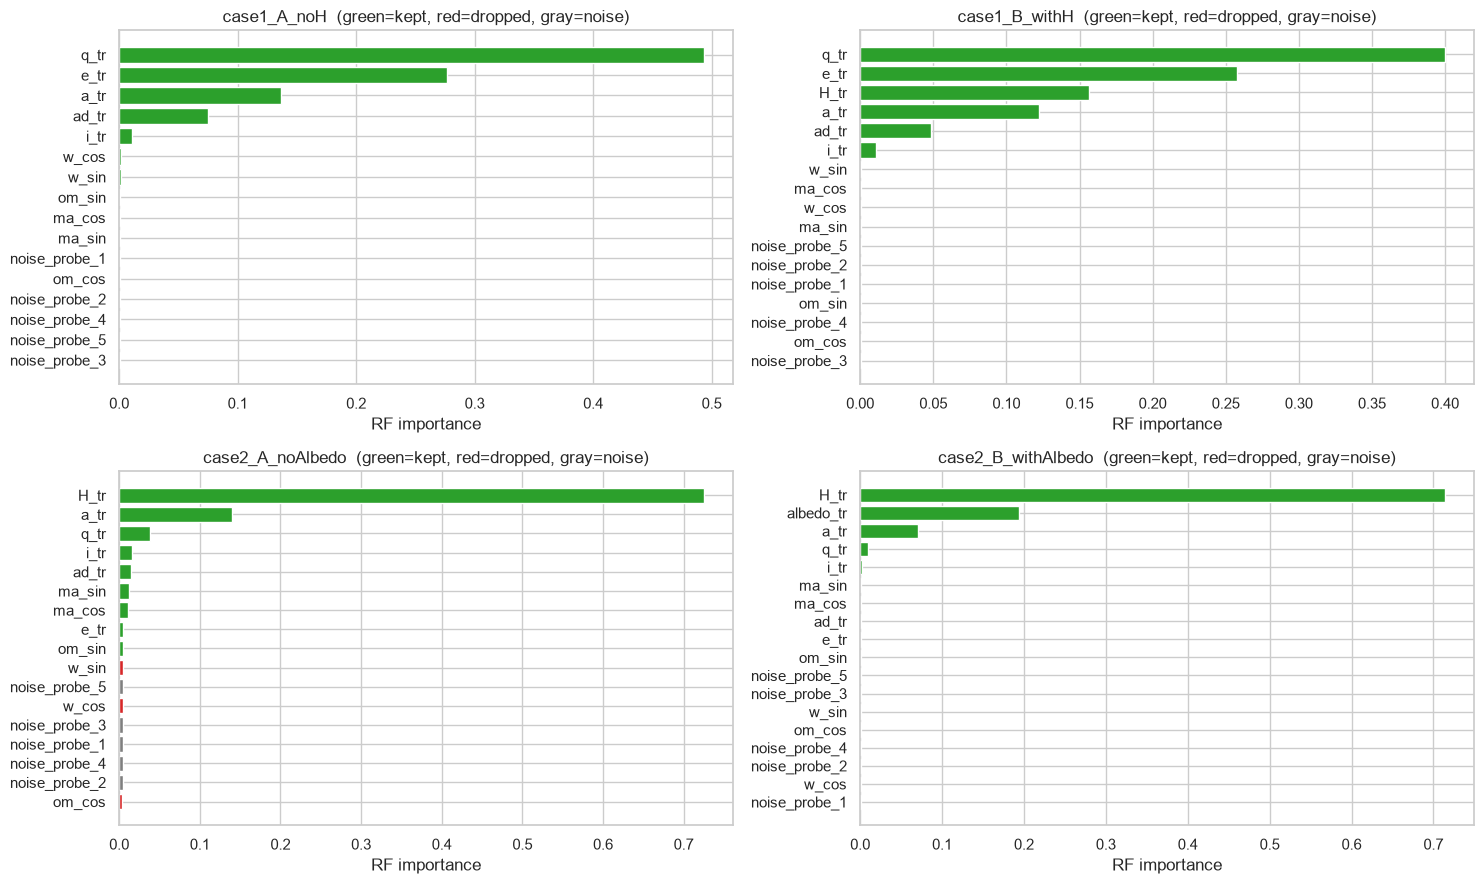

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, (k, r) in zip(axes.ravel(), sel_results.items()):
    s = r["RF_importance"].sort_values()
    colors = ["tab:gray" if i.startswith("noise_probe") else ("tab:green" if i in final_sets[k] else "tab:red") for i in s.index]
    ax.barh(s.index, s.values, color=colors); ax.set_title(f"{k}  (green=kept, red=dropped, gray=noise)")
    ax.set_xlabel("RF importance")
savefig("03_feature_selection_rf")

## 8. Save processed datasets + manifest

In [15]:
def save_df(d, name):
    d = d.copy()
    for c in d.select_dtypes("float64").columns: d[c] = d[c].astype("float32")
    try:
        p = PROC / f"{name}.parquet"; d.to_parquet(p, index=False)
    except Exception as e:
        print("parquet unavailable, falling back to csv.gz:", type(e).__name__)
        p = PROC / f"{name}.csv.gz"; d.to_csv(p, index=False, compression="gzip")
    print(f"saved {p.name:28s} {len(d):>8,} rows x {d.shape[1]} cols  ({p.stat().st_size/1e6:.1f} MB)")
    return p.name

RAW_KEEP = ["a", "e", "i", "q", "ad", "n", "per_y", "H", "albedo", "om", "w", "ma"]
TR_KEEP  = [f"{c}_tr" for c in feat_for_model] + ANGLES

files = {
    "case1": save_df(c1[["full_name", "class", "y_pha", "split"] + RAW_KEEP + TR_KEEP], "case1_pha"),
    "case2": save_df(c2[["full_name", "class", "log_diameter", "diameter", "split"] + RAW_KEEP + TR_KEEP], "case2_diameter"),
    "case3": save_df(c3[["full_name", "class", "neo", "pha"] + RAW_KEEP + TR_KEEP], "case3_orbits"),
}

manifest = {
    "seed": SEED,
    "files": files,
    "transforms": chosen,                     # per raw feature: none | sqrt | cbrt | log10 (x + 1e-6)
    "feature_sets": final_sets,
    "targets": {"case1": "y_pha", "case2": "log_diameter (log10 km)"},
    "split_column": "split (train/test, decided in 03)",
    "excluded_from_case1": ["moid", "moid_ld", "neo", "class"],
}
(RES_DIR / "03_manifest.json").write_text(json.dumps(manifest, indent=2))
pd.DataFrame(clean_log).to_csv(RES_DIR / "03_cleaning_log.csv", index=False)
skew_tbl.to_csv(RES_DIR / "03_skew_table.csv")
for k, r in sel_results.items(): r.to_csv(RES_DIR / f"03_feature_rank_{k}.csv")
print(json.dumps(manifest["feature_sets"], indent=2))

saved case1_pha.parquet             938,599 rows x 31 cols  (110.5 MB)
saved case2_diameter.parquet        132,045 rows x 32 cols  (21.2 MB)
saved case3_orbits.parquet          958,520 rows x 31 cols  (112.5 MB)
{
  "case1_A_noH": [
    "q_tr",
    "e_tr",
    "a_tr",
    "ad_tr",
    "i_tr",
    "ma_cos",
    "w_cos",
    "w_sin",
    "ma_sin"
  ],
  "case1_B_withH": [
    "q_tr",
    "e_tr",
    "a_tr",
    "H_tr",
    "ad_tr",
    "i_tr",
    "ma_cos",
    "w_sin"
  ],
  "case2_A_noAlbedo": [
    "H_tr",
    "a_tr",
    "q_tr",
    "ad_tr",
    "i_tr",
    "e_tr",
    "ma_sin",
    "om_sin",
    "ma_cos"
  ],
  "case2_B_withAlbedo": [
    "H_tr",
    "albedo_tr",
    "a_tr",
    "q_tr",
    "ad_tr",
    "i_tr",
    "e_tr",
    "ma_cos",
    "ma_sin"
  ],
  "case3_core": [
    "a_tr",
    "e_tr",
    "i_tr"
  ],
  "case3_with_angles": [
    "a_tr",
    "e_tr",
    "i_tr",
    "om_sin",
    "om_cos",
    "w_sin",
    "w_cos",
    "ma_sin",
    "ma_cos"
  ]
}


### Cleaning log

In [16]:
pd.DataFrame(clean_log)

,step,rows_before,rows_after,action
0,raw load,958524,958524,-
1,duplicates,958524,958524,drop exact duplicates and repeated full_name (...
2,hyperbolic orbits,958524,958520,drop e>=1 or a<=0
3,"albedo not in (0,1]",958520,958520,0 values -> NaN
4,diameter <= 0,958520,958520,0 values -> NaN
5,"H not in [0,35]",958520,958520,3 values -> NaN
6,case1 rows,958520,938599,pha labelled & H present
7,case2 rows,958520,132045,diameter & H present
8,case3 rows,958520,958520,all bound orbits


## Findings & decisions (fill in after running)
- Rows removed in total, and why: 
- Transform chosen for `a`, `per_y`, `q`: 
- Did any angle feature beat the noise probe? 
- Case 1: features kept **without** H / **with** H: 
- Case 2: features kept **without** albedo / **with** albedo: 
- Next: `04_pha_classification.ipynb` (load `03_manifest.json`, use the `split` column, pipelines with scaler/SMOTE fitted on train only)